# Animation vs. Small Multiples

**Family:** Bad vs. good &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Basic

> *Bad vs. good:* Common chart mistakes, each shown next to a better alternative that fixes it.

## Design purpose

Animation shows one moment at a time, so comparing frames depends on the reader's memory. Did East grow between March and October? In an animation you have to remember March's bar while watching October's. Research on animated transitions (e.g. Robertson et al., 2008) found animation engaging but worse for analysis than static small multiples.

## When to use

- Use small multiples when readers must compare states over time or find the trend
- Use a single line chart when the trend of a few series is the message
- Keep animation for presentations and storytelling, alongside a static chart

## Avoid when

- Animating data the audience must analyse or compare
- Animation as the only view in a report, dashboard or PDF

## Alternatives

- Small multiples (one panel per period, shared axes)
- Line chart of the series over time
- Slope chart (first vs. last period)

## Design tips

- If you animate, also provide the static version
- Share axes across all panels so differences are real
- Highlight the entity that carries the message and gray the rest

## Example

Monthly sales (US$ k) for six regions over 12 months; East grows steadily while the others stay flat.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(4)
regions = ["North", "South", "East", "West", "Central", "Coast"]
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
base = np.array([62, 55, 38, 58, 50, 45], dtype=float)
sales = base + rng.normal(0, 4, (12, 6))
sales[:, 2] += np.linspace(0, 30, 12)                  # East grows steadily
df = pd.DataFrame(sales.round(1), index=months, columns=regions)
df.iloc[[0, 6, 11]]

,North,South,East,West,Central,Coast
Jan,59.4,54.3,44.7,60.6,43.4,45.0
Jul,65.8,51.1,51.2,57.2,53.0,48.4
Dec,58.0,59.9,64.9,53.0,58.2,44.5


### Plot

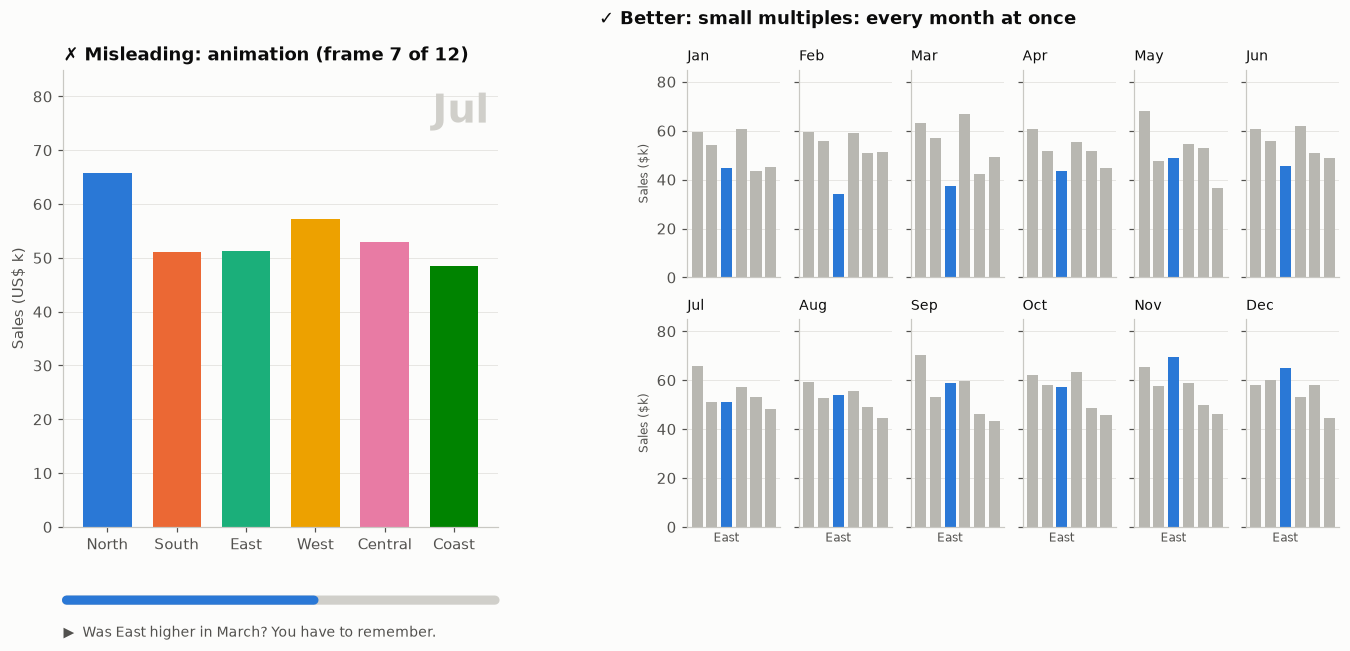

In [3]:
fig = plt.figure(figsize=(13, 5.4))
left, right = fig.subfigures(1, 2, width_ratios=[1, 1.5], wspace=0.04)

# Left: one frame of the animation, with a player bar.
ax = left.subplots()
frame = 6
ax.bar(regions, df.iloc[frame], color=PALETTE[:6], width=0.7)
ax.set_ylim(0, 85)
ax.set_ylabel("Sales (US$ k)")
ax.grid(axis="x", visible=False)
ax.set_title("✗ Misleading: animation (frame 7 of 12)", loc="left", fontsize=12)
ax.text(0.98, 0.95, months[frame], transform=ax.transAxes, ha="right", va="top",
        fontsize=26, fontweight="bold", color="#d0cfca")
ax.annotate("", xy=(1, -0.16), xytext=(0, -0.16), xycoords="axes fraction",
            arrowprops=dict(arrowstyle="-", color="#d0cfca", linewidth=6))
ax.annotate("", xy=((frame + 1) / 12, -0.16), xytext=(0, -0.16), xycoords="axes fraction",
            arrowprops=dict(arrowstyle="-", color=PALETTE[0], linewidth=6))
ax.text(0, -0.24, "▶  Was East higher in March? You have to remember.", transform=ax.transAxes,
        fontsize=9, color="#52514e")

# Right: small multiples with shared axes, East highlighted.
right.suptitle("✓ Better: small multiples: every month at once", x=0.02, ha="left",
               fontsize=12, fontweight="bold")
axes = right.subplots(2, 6, sharex=True, sharey=True)
colors = [PALETTE[0] if r == "East" else GRAY for r in regions]
for ax, month in zip(axes.flat, months):
    ax.bar(range(6), df.loc[month], color=colors, width=0.75)
    ax.set_title(month, fontsize=9, fontweight="normal")
    ax.set_xticks([2], ["East"], fontsize=8)
    ax.tick_params(axis="x", length=0)
    ax.grid(axis="x", visible=False)
    ax.set_ylim(0, 85)
axes[0, 0].set_ylabel("Sales ($k)", fontsize=8)
axes[1, 0].set_ylabel("Sales ($k)", fontsize=8)
plt.show()

## How to read it

On the left is the animation's July frame: nothing stands out, and no earlier frame is visible to compare against. On the right, all twelve months sit side by side, and East's steady climb is obvious at a glance.

---
Standalone script: [`animation_vs_small_multiples.py`](animation_vs_small_multiples.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)